In [35]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

## **Visualise Results**

#### **Levelized Cost**

In [75]:
cost_lcoh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoh.xlsx")
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_capex =pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex.xlsx")

In [ ]:
cost_lcoe["entity_base_mapping"].value_counts()

#### Select Entities

In [76]:
# ---------------------------------------- ENTITY BASE MAPPING -----------------------------------

cost_lcoh = cost_lcoh[cost_lcoh["entity_base_mapping"].isin(['Hydrogen'])]
cost_lcos = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['Battery'])]
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV', 'Wind Turbine'])]
cost_capex = cost_capex[cost_capex["entity_base_mapping"].isin(['PV', 'Wind Turbine', 'Electrolyzer'])]


# ---------------------------------------- ENTITY MAPPING -----------------------------------

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Battery', 'Lithium-Ion Battery', 'Lead Acid Battery'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Lithium-Ion Battery': 'Lithium Ion',
#     'Lead Acid Battery': 'Lead Acid',
#     'Nickel-Iron Battery': 'Nickel-Iron',
#     'Lithium Iron Phosphate Battery': 'Lithium Iron Phosphate',
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Wind Turbine', 'Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Wind Turbine': 'Wind Turbine',
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore',
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['PVSystem', 'Hybrid PV System', 'Utility-scale PV System'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'PVSystem': 'PV',
#     'Hybrid PV System': 'Hybrid',
#     'Utility-scale PV System': 'Utility-scale',
#     'Rooftop PV System': 'Rooftop',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Hybrid Energy System', 'Hybrid Renewable Energy System (HRES)'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Hybrid Energy System': 'HES',
#     'Hybrid Renewable Energy System (HRES)' : 'HRES',
# })


# cost_lcoh = cost_lcoh[cost_lcoh["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])]
# cost_lcoh["entity_mapping"] = cost_lcoh["entity_mapping"].replace({
#     'Hydrogen': 'Hydrogen',
#     'Blue Hydrogen': 'Blue',
#     'Grey Hydrogen': 'Grey',
#     'Yellow Hydrogen': 'Yellow',
#     'Green Hydrogen': 'Green'
# })

In [77]:
# cost_lcoh = visualisation.convert_spatial(cost_lcoh)
# print(cost_lcoh["entity_base_mapping"].value_counts())

cost_lcoe = visualisation.convert_spatial(cost_lcoe)
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV              589
Wind Turbine    274
Name: count, dtype: int64


In [ ]:
len(cost_lcoe[cost_lcoe["value_converted"] < 0.1])

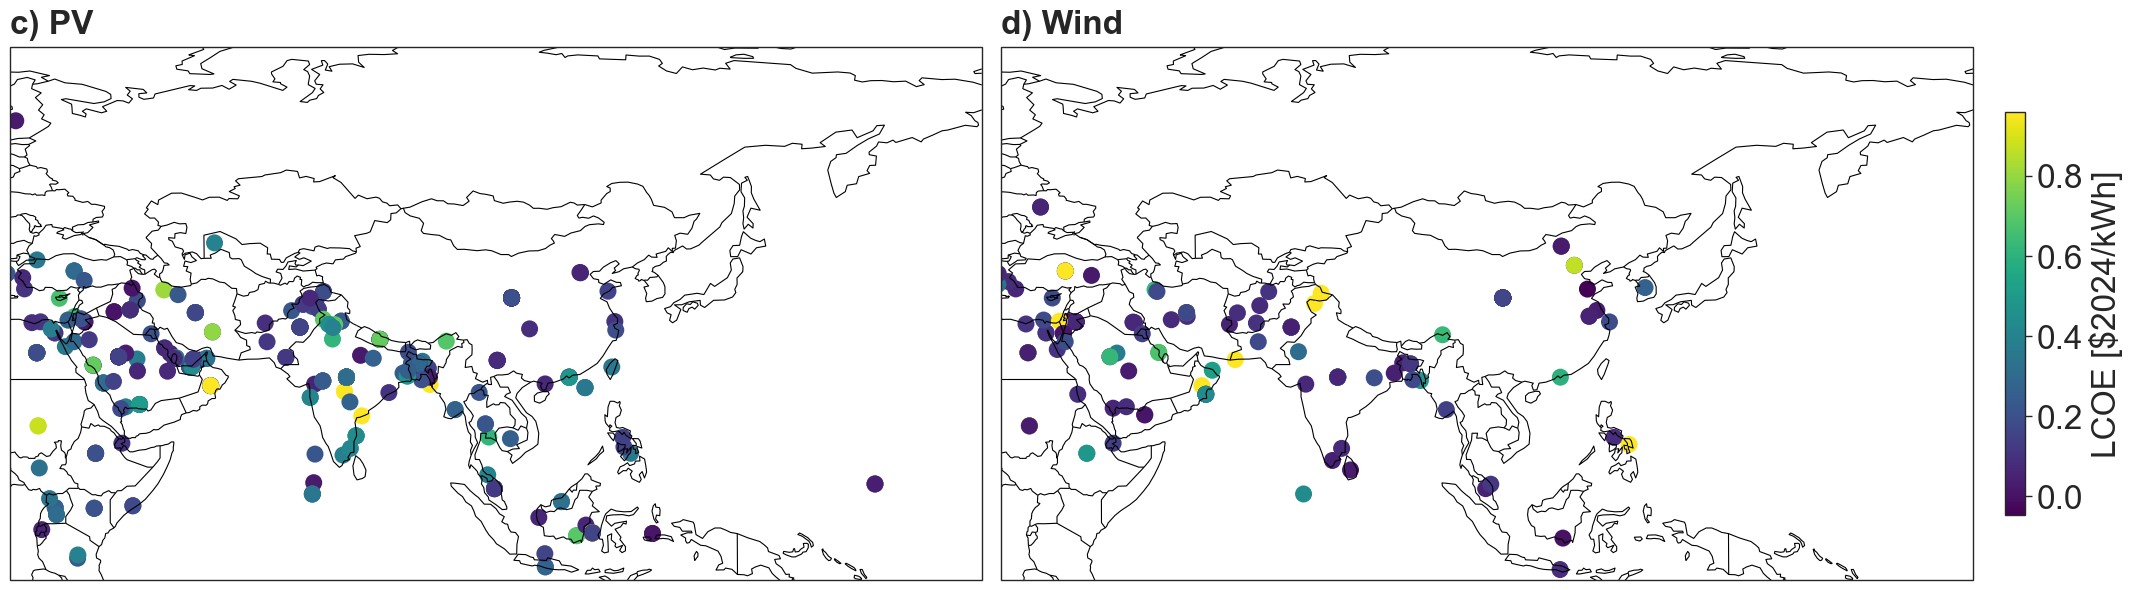

In [100]:
datasets = [
    {
    'df': cost_lcoe[cost_lcoe["entity_mapping"] == "PV"],
    'value_column': 'value_converted',
    #'entity_column': 'entity_mapping', 
    'title': 'c) PV'
    },
    {
    'df': cost_lcoe[cost_lcoe["entity_mapping"] == "Wind Turbine"],
    'value_column': 'value_converted',
    #'entity_column': 'entity_mapping', 
    'title': 'd) Wind'
    }
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOE [$2024/kWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=24,
    continent="Asia"
)

fig.savefig("../data/figures/results/cost/lcoe_asia.pdf", bbox_inches='tight')

#### **Lifetime**

In [87]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
lifetime = df[df["property_mapping"] == "Lifetime"]
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]    2945
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]      172
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         16
[{'exponent': 1.0, 'text': 'yrs', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]        11
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           3
[{'exponent': 1.0, 'text': 'Years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       3
[{'exponent': 1.0, 'text': 'y', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           3
Name: count, dtype: int64

#### Select Entities

In [88]:
lifetime = visualisation.convert_spatial(lifetime)
print(lifetime["entity_base_mapping"].value_counts())
len(lifetime)

entity_base_mapping
PV                      221
Wind                     82
Battery                  74
Hybrid Energy System     38
Coal                     37
Hydrogen                 24
Natural Gas              11
Electrolyzer             11
Name: count, dtype: int64


498

In [91]:
lifetime_wind = lifetime[lifetime["entity_base_mapping"].isin(['Wind'])]
lifetime_pv = lifetime[lifetime["entity_base_mapping"].isin(['PV'])]

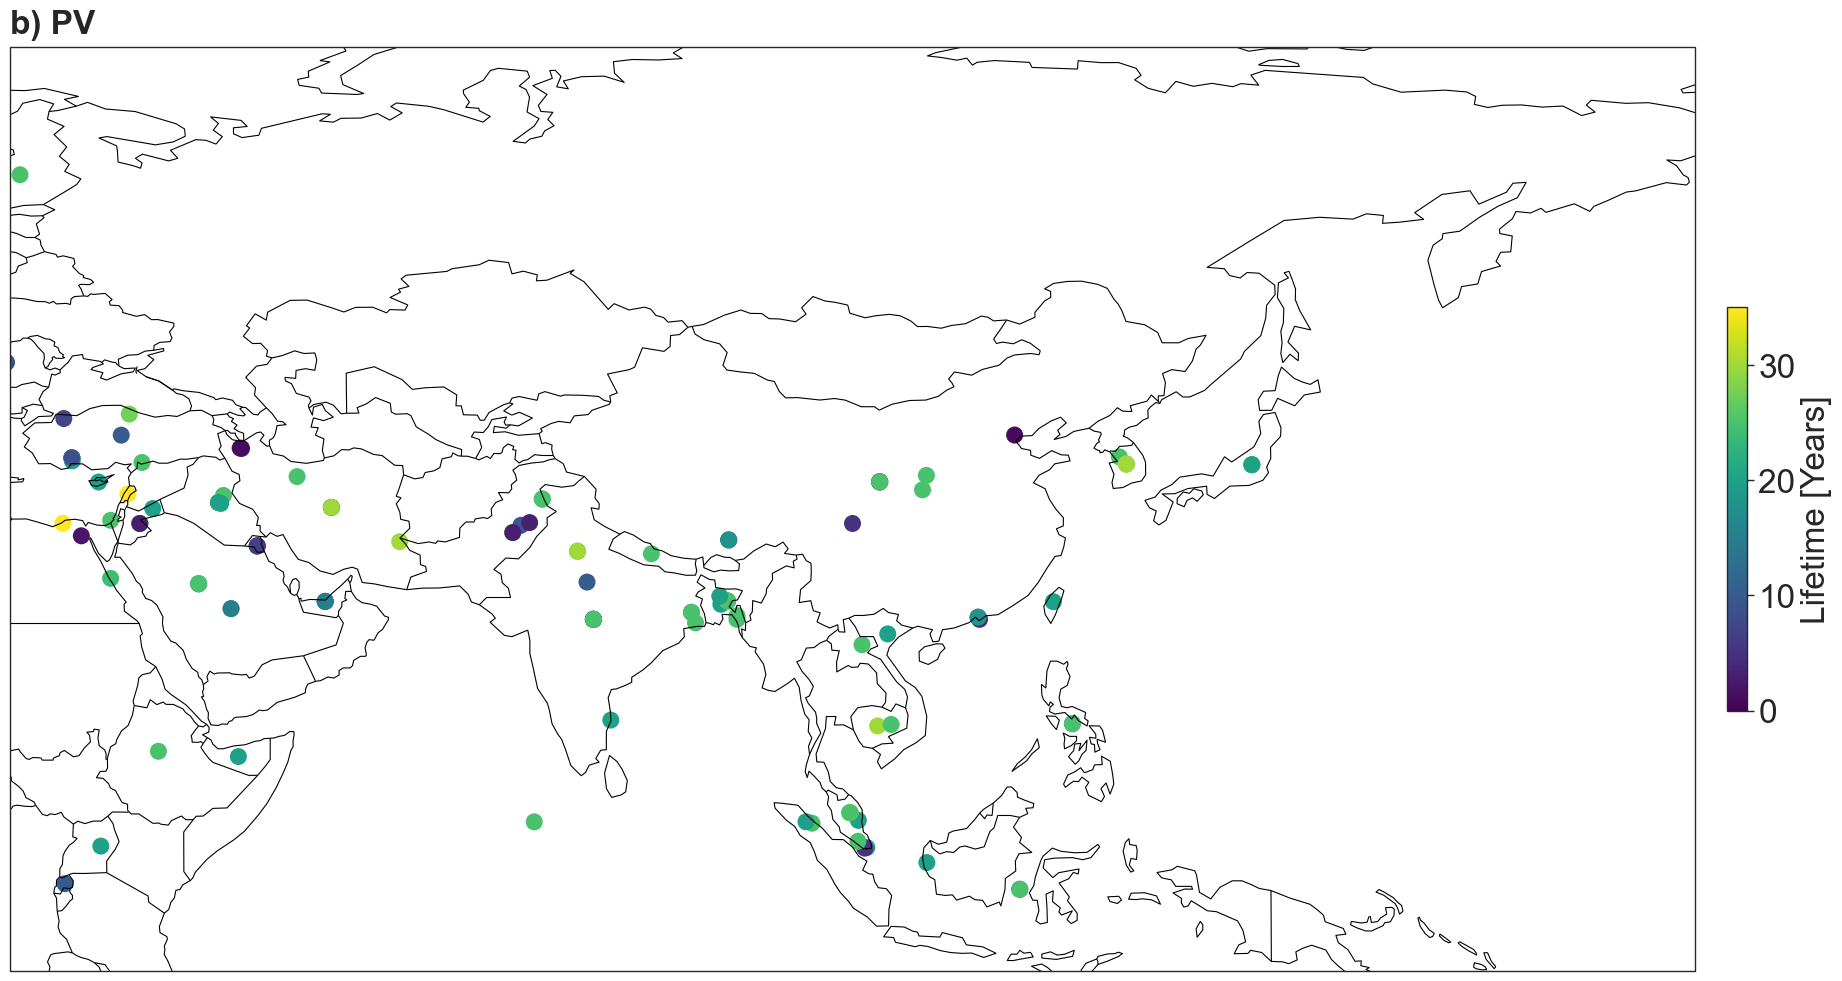

In [105]:
datasets = [
    # {
    # 'df': lifetime_wind,
    # 'value_column': 'value_normalized',
    # #'entity_column': 'entity_base_mapping', 
    # 'title': 'a) Wind'
    # },
    {
    'df': lifetime_pv,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'b) PV'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Lifetime [Years]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=24,
    log_scale=False,
    continent='Asia'
)
# fig.savefig("../data/figures/results/lifetime/lifetime_worldmap.pdf", bbox_inches='tight')

#### **Efficiency**

In [94]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          9529
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]      41
Name: count, dtype: int64

#### Select Entities

In [95]:
efficiency = visualisation.convert_spatial(efficiency)
print(efficiency["entity_base_mapping"].value_counts())

entity_base_mapping
PV                      416
Wind                     80
Hydrogen                 77
Coal                     53
Battery                  51
Electrolyzer             50
Natural Gas              48
Hybrid Energy System     37
Name: count, dtype: int64


In [96]:
efficiency_wind = efficiency[efficiency["entity_base_mapping"].isin(['Wind'])]
efficiency_pv = efficiency[efficiency["entity_base_mapping"].isin(['PV'])]

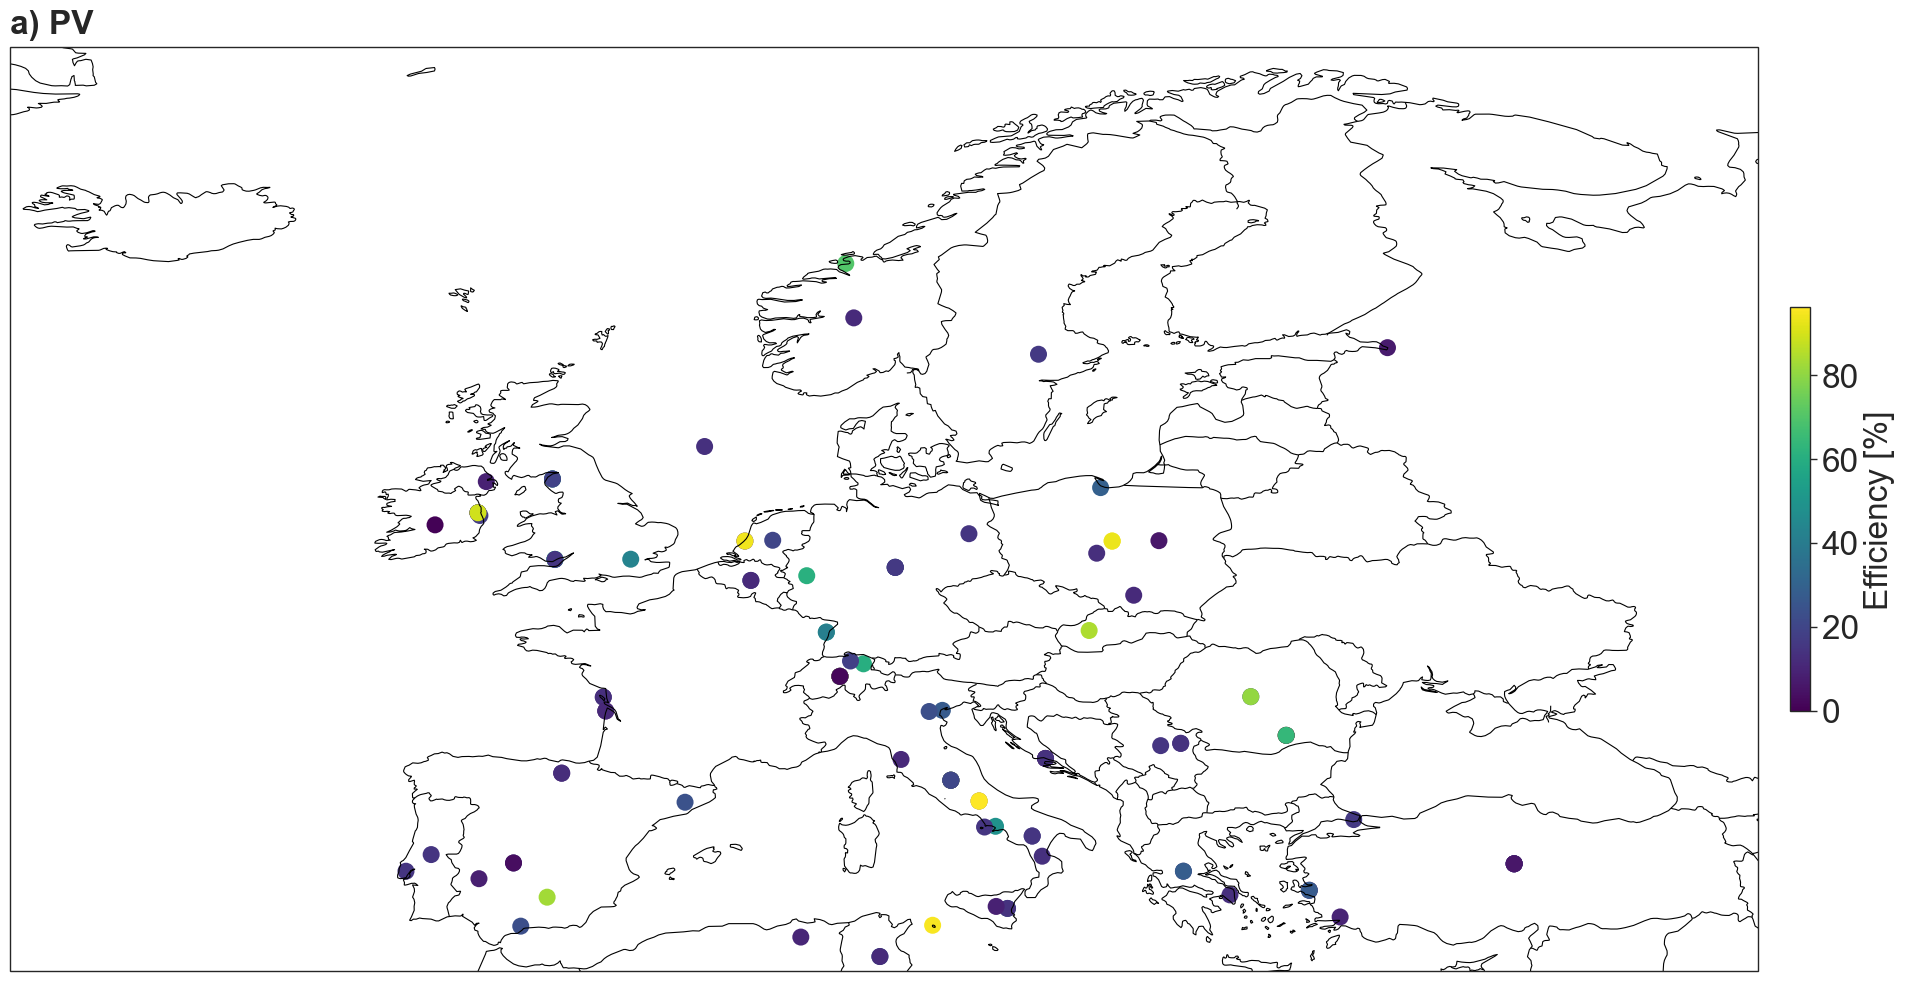

In [104]:
datasets = [
    #{
    # 'df': efficiency_wind,
    # 'value_column': 'value_normalized',
    # #'entity_column': 'entity_base_mapping', 
    # 'title': 'c) Wind'
    # },
    {
    'df': efficiency_pv,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'a) PV'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Efficiency [%]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=24,
    continent='Europe'

)
#fig.savefig("../data/figures/results/efficiency/efficiency_worldmap.pdf", bbox_inches='tight')

#### **Capacity**

In [116]:
capacity = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_gw.xlsx")

In [4]:
capacity["entity_base_mapping"].value_counts()

entity_base_mapping
Wind Turbine            5207
PV                      4591
Electrolyzer             546
Coal                     506
Hydrogen                 275
Battery                  269
Natural Gas              156
Hybrid Energy System      78
Name: count, dtype: int64

In [122]:
capacity = capacity[capacity["value_converted"] < 5]
capacity = capacity[capacity["value_converted"] > 0.1]

#### Select Entities

In [123]:
capacity_pv = capacity[capacity["entity_base_mapping"].isin(['PV'])]
capacity_wind = capacity[capacity["entity_base_mapping"].isin(['Wind Turbine'])]

#capacity = capacity[capacity["entity_mapping"].isin(['PVSystem', 'Wind Turbine'])]

#capacity_wind = capacity[capacity["entity_mapping"].isin(['Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# capacity_wind["entity_mapping"] = capacity_wind["entity_mapping"].replace({
#     'Offshore Wind Turbine': 'Offshore Wind',
#     'Onshore Wind Turbine': 'Onshore Wind'
# })

# capacity = capacity[capacity["entity_mapping"].isin(['Hybrid PV System', 'Utility-scale PV System', 'Rooftop PV System', 'Photovoltaic-Thermal System (PVT)'])]
# capacity["entity_mapping"] = capacity["entity_mapping"].replace({
#     'Hybrid PV System': 'Hybrid PV',
#     'Utility-scale PV System': 'Utility-scale PV',
#     'Rooftop PV System': 'Rooftop PV',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

In [124]:
capacity_wind = visualisation.convert_spatial(capacity_wind)
print(capacity_wind["entity_mapping"].value_counts().iloc[:20])

capacity_pv = visualisation.convert_spatial(capacity_pv)
print(capacity_pv["entity_mapping"].value_counts().iloc[:20])

entity_mapping
Wind Turbine             508
Offshore Wind Turbine     67
Onshore Wind Turbine      21
Large Wind Turbine         7
Small Wind Turbine         1
Name: count, dtype: int64
entity_mapping
PV                               267
Rooftop PV                         6
Utility-scale PV                   6
Ground-mounted PV                  2
Floating PV (FPV)                  2
Photovoltaic-Thermal (PVT)         1
Building-Integrated PV (BIPV)      1
Name: count, dtype: int64


In [ ]:
capacity["entity"].value_counts().head(20)

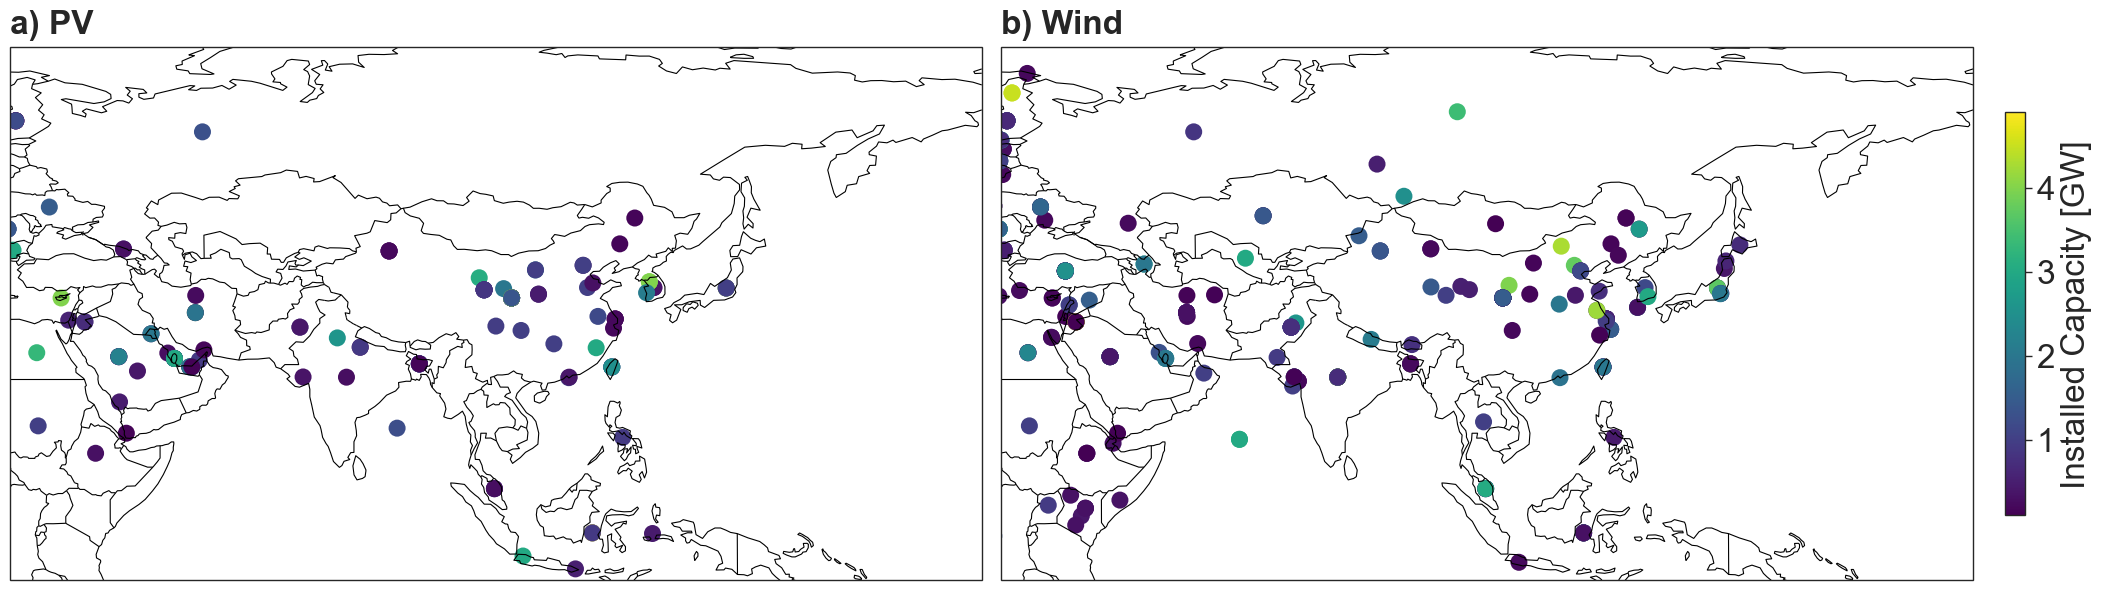

In [127]:
datasets = [
    {
    'df': capacity_pv,
    'value_column': 'value_converted',
    #'entity_column': 'entity_base_mapping', 
    'title': 'a) PV'
    },
    {
    'df': capacity_wind,
    'value_column': 'value_converted',
    #'entity_column': 'entity_mapping', 
    'title': 'b) Wind'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Installed Capacity [GW]",
    figsize=(26, 12),
    #log_scale=True,
    default_point_size=150,
    font_size=24,
    continent='Asia',
)
fig.savefig("../data/figures/results/capacity/capacity_asia.pdf", bbox_inches='tight')

#### **Spatial Distribution of Mentions (PV & Wind)**

In [7]:
# Load full dataset and filter for PV and Wind
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")

df_pv = df[df["entity_base_mapping"].isin(['PV'])]
df_wind = df[df["entity_base_mapping"].isin(['Wind'])]

In [8]:
wind = visualisation.convert_spatial(df_wind)
pv = visualisation.convert_spatial(df_pv)

print(f"PV mentions with location: {len(pv)}")
print(f"Wind mentions with location: {len(wind)}")

PV mentions with location: 6489
Wind mentions with location: 4950


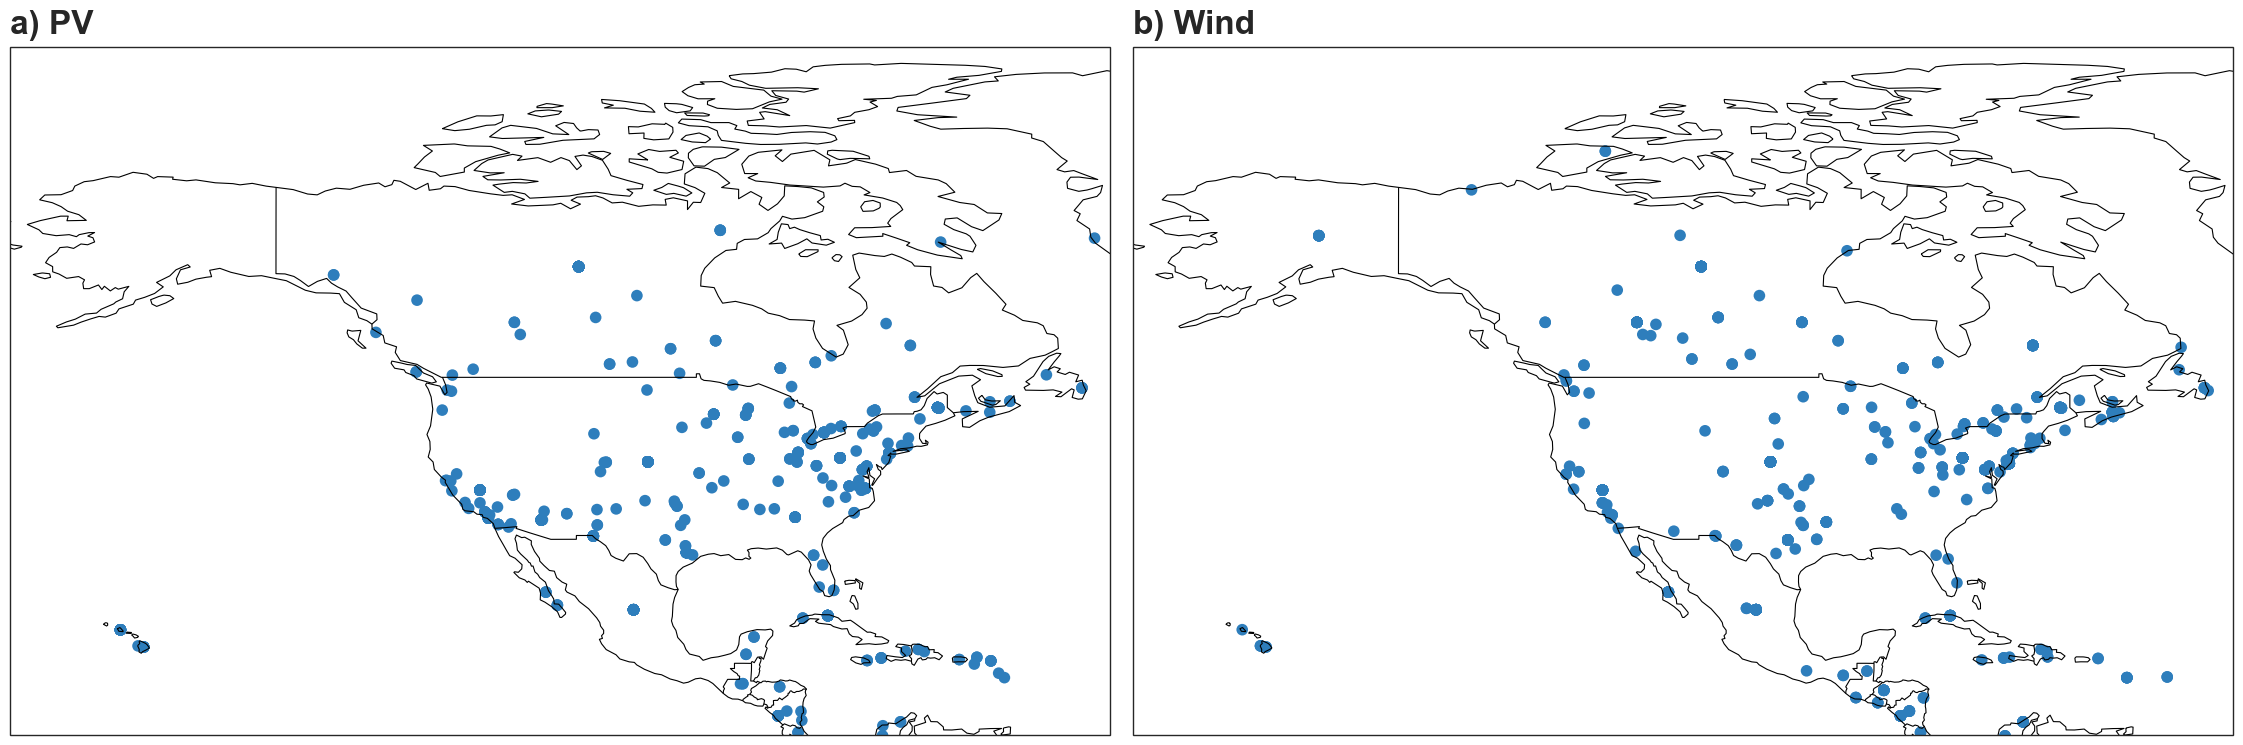

In [29]:
# Plot spatial distribution of mentions (no value encoding, just locations)
datasets = [
    {
        'df': pv,
        #'value_column': 'dummy_value',
        'title': 'a) PV'
    },
    {
        'df': wind,
        #'value_column': 'dummy_value',
        'title': 'b) Wind'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title=None,  # No colorbar needed
    figsize=(26, 12),
    jitter_strength=0.5,  # Add some jitter to avoid overlapping
    default_point_size=70,
    font_size=24,
    cmap="Blues",  # Single color since all values are the same
    apply_iqr=False,  # No filtering needed
    continent='North America'
)
#fig.savefig("../data/figures/results/spatial_mentions_pv_wind.pdf", bbox_inches='tight')